# Step 6 — Seating, at 10 and 15 players

Deliverable 03's step 7 changed only the seating at 5 players and found that it changes which
policy is learned: under ranked seating the agent found the equilibrium, under random seating
it played close to `shoot_strongest`. Step 3 of this folder found a deep U-shaped targeting
profile at 10 and 15 players under ranked seating. This step asks whether random seating still
moves the agent towards `shoot_strongest` when the field is larger.

One dial moves: `ranked` against `random`. The reward stays `terminal`, and every other
setting matches step 1.

In [1]:
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from gruel_env import GruelEnv, N_ACTIONS, MISS, SHOOT_LEFT, SHOOT_RIGHT

torch.set_num_threads(1)
print("torch", torch.__version__)

torch 2.2.2


## Settings

In [2]:
PLAYER_COUNTS = [10, 15]
ARMS = ["ranked", "random"]
REWARD = "terminal"
SEEDS = [0, 1, 2]

OBSERVATION_SIZE = 4
HIDDEN_SIZE = 64

UPDATES = 2000
EPISODES_PER_UPDATE = 96
EVALUATION_EPISODES = 10000
REFERENCE_EPISODES = 10000

LEARNING_RATE = 0.003
CLIP = 0.2
EPOCHS = 4
MINIBATCH_SIZE = 256
VALUE_COEFFICIENT = 0.5
ENTROPY_COEFFICIENT = 0.01

# The same threshold as deliverable 03's steps 7 and 8: two targeting profiles are the same
# policy if their mean distance, rank by rank, is at most this.
MATCH_THRESHOLD = 0.10

print("player counts:", PLAYER_COUNTS, " arms:", ARMS, " reward:", REWARD)
print("budget per run:", UPDATES, "updates x", EPISODES_PER_UPDATE, "episodes =",
      UPDATES * EPISODES_PER_UPDATE, "training episodes")
print("seeds:", SEEDS)

player counts: [10, 15]  arms: ['ranked', 'random']  reward: terminal
budget per run: 2000 updates x 96 episodes = 192000 training episodes
seeds: [0, 1, 2]


## The agent and the measurement machinery, copied forward

Every definition below is step 1's, copied forward. Rule 1 says a step copies the
previous step forward rather than importing it, so this folder carries its own copy and
can be handed over on its own.

One change: `play_episodes` also records how long each episode lasted and what every
player had banked by the end, because the shaped reward pays throughout the episode and
both numbers are needed to check it.

`collect_batch` reads each player's return from the environment rather than assuming
`1.0 for the winner, 0.0 for everyone else`. Under `terminal` the two are identical, so
nothing here depends on it; it matters the moment a shaped reward is used.

In [3]:
class SharedActorCritic(nn.Module):
    def __init__(self, n_players):
        super().__init__()
        self.n_players = n_players
        self.actor_first = nn.Linear(OBSERVATION_SIZE, HIDDEN_SIZE)
        self.actor_second = nn.Linear(HIDDEN_SIZE, N_ACTIONS)
        critic_input_size = 2 * n_players + n_players
        self.critic_first = nn.Linear(critic_input_size, HIDDEN_SIZE)
        self.critic_second = nn.Linear(HIDDEN_SIZE, 1)
        self.activation = nn.Tanh()

    def action_logits(self, observation):
        hidden = self.activation(self.actor_first(observation))
        return self.actor_second(hidden)

    def value(self, state, agent_one_hot):
        combined = torch.cat([state, agent_one_hot], dim=-1)
        hidden = self.activation(self.critic_first(combined))
        return self.critic_second(hidden).squeeze(-1)


def global_state(game):
    numbers = []
    for position in range(game.n):
        numbers.append(game.accuracies[position])
        if position in game.order:
            numbers.append(1.0)
        else:
            numbers.append(0.0)
    return np.array(numbers, dtype=np.float32)


def one_hot(position, n_players):
    vector = np.zeros(n_players, dtype=np.float32)
    vector[position] = 1.0
    return vector


def collect_batch(model, game, episodes):
    observations = {p: [] for p in range(game.n)}
    actions = {p: [] for p in range(game.n)}
    old_log_probabilities = {p: [] for p in range(game.n)}
    values = {p: [] for p in range(game.n)}
    returns = {p: [] for p in range(game.n)}
    states = {p: [] for p in range(game.n)}
    agent_flags = {p: [] for p in range(game.n)}

    for _ in range(episodes):
        game.reset()
        episode_observations = {p: [] for p in range(game.n)}
        episode_actions = {p: [] for p in range(game.n)}
        episode_log_probabilities = {p: [] for p in range(game.n)}
        episode_values = {p: [] for p in range(game.n)}
        episode_states = {p: [] for p in range(game.n)}
        episode_flags = {p: [] for p in range(game.n)}
        # What each player had already banked when it made each decision. Needed because
        # the return for a decision is whatever arrives AFTER it, and under `shaped`
        # rewards arrive throughout the episode rather than only at the end.
        episode_banked_before = {p: [] for p in range(game.n)}

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()

            # A finished agent is handed to us one last time, so PettingZoo can retire
            # it. Stepping with None is how we say 'nothing to do here'.
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            banked_so_far = float(game.episode_returns[acting_agent])
            observation_tensor = torch.from_numpy(observation)
            state_array = global_state(game)
            agent_array = one_hot(actor, game.n)

            with torch.no_grad():
                logits = model.action_logits(observation_tensor)
                value = model.value(torch.from_numpy(state_array),
                                    torch.from_numpy(agent_array))

            distribution = torch.distributions.Categorical(logits=logits)
            action = distribution.sample()

            episode_observations[actor].append(observation)
            episode_actions[actor].append(int(action))
            episode_log_probabilities[actor].append(float(distribution.log_prob(action)))
            episode_values[actor].append(float(value))
            episode_states[actor].append(state_array)
            episode_flags[actor].append(agent_array)
            episode_banked_before[actor].append(banked_so_far)

            game.step(int(action))

        for position in range(game.n):
            # The return for a decision is the reward-to-go: everything this player ended
            # the episode with, minus what it had already banked when it decided. With a
            # discount of 1 that is exactly the undiscounted sum of what came after.
            #
            # Reading it from the environment is the whole point of this step. Assuming
            # `1.0 for the winner, 0.0 for everyone else` is correct under `terminal` and
            # silently WRONG under `shaped`, where it would discard every kill bonus,
            # every elimination penalty and every survival tick -- and both arms would then
            # train on identical numbers and look identical for a reason that is a bug.
            name = game.agent_of_position[position]
            final_total = float(game.episode_returns[name])
            for index in range(len(episode_actions[position])):
                own_return = final_total - episode_banked_before[position][index]
                observations[position].append(episode_observations[position][index])
                actions[position].append(episode_actions[position][index])
                old_log_probabilities[position].append(
                    episode_log_probabilities[position][index])
                values[position].append(episode_values[position][index])
                states[position].append(episode_states[position][index])
                agent_flags[position].append(episode_flags[position][index])
                returns[position].append(own_return)

    flat_observations = []
    flat_actions = []
    flat_old_log_probabilities = []
    flat_values = []
    flat_returns = []
    flat_states = []
    flat_flags = []
    for position in range(game.n):
        flat_observations.extend(observations[position])
        flat_actions.extend(actions[position])
        flat_old_log_probabilities.extend(old_log_probabilities[position])
        flat_values.extend(values[position])
        flat_returns.extend(returns[position])
        flat_states.extend(states[position])
        flat_flags.extend(agent_flags[position])

    batch = {
        "observations": torch.tensor(np.array(flat_observations), dtype=torch.float32),
        "actions": torch.tensor(flat_actions, dtype=torch.long),
        "old_log_probabilities": torch.tensor(flat_old_log_probabilities,
                                              dtype=torch.float32),
        "values": torch.tensor(flat_values, dtype=torch.float32),
        "returns": torch.tensor(flat_returns, dtype=torch.float32),
        "states": torch.tensor(np.array(flat_states), dtype=torch.float32),
        "agent_flags": torch.tensor(np.array(flat_flags), dtype=torch.float32),
    }
    return batch


def ppo_update(model, optimiser, batch, update_rng):
    advantages = batch["returns"] - batch["values"]
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    count = len(batch["actions"])
    order = np.arange(count)

    for epoch in range(EPOCHS):
        update_rng.shuffle(order)
        for start in range(0, count, MINIBATCH_SIZE):
            chunk = order[start:start + MINIBATCH_SIZE]
            index = torch.from_numpy(chunk)

            logits = model.action_logits(batch["observations"][index])
            distribution = torch.distributions.Categorical(logits=logits)
            new_log_probabilities = distribution.log_prob(batch["actions"][index])

            ratio = torch.exp(new_log_probabilities
                              - batch["old_log_probabilities"][index])
            minibatch_advantages = advantages[index]
            unclipped = ratio * minibatch_advantages
            clipped = torch.clamp(ratio, 1 - CLIP, 1 + CLIP) * minibatch_advantages
            policy_loss = -torch.min(unclipped, clipped).mean()

            entropy = distribution.entropy().mean()

            predicted_value = model.value(batch["states"][index],
                                          batch["agent_flags"][index])
            value_loss = ((predicted_value - batch["returns"][index]) ** 2).mean()

            total_loss = (policy_loss
                          + VALUE_COEFFICIENT * value_loss
                          - ENTROPY_COEFFICIENT * entropy)

            optimiser.zero_grad()
            total_loss.backward()
            optimiser.step()


def make_agent_policy(model):
    def agent_policy(game, actor):
        name = game.agent_of_position[actor]
        observation = game.observe(name)
        with torch.no_grad():
            logits = model.action_logits(torch.from_numpy(observation))
        distribution = torch.distributions.Categorical(logits=logits)
        return int(distribution.sample())
    return agent_policy


def play_episodes(game, policy, episodes):
    records = []
    for _ in range(episodes):
        game.reset()
        decisions = []

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            action = policy(game, actor)

            # Recorded BEFORE stepping, because a kill contracts the circle.
            left, right = game.neighbours(actor)
            decisions.append({
                "accuracy": round(float(game.accuracies[actor]), 4),
                "action": action,
                "left_accuracy": round(float(game.accuracies[left]), 4),
                "right_accuracy": round(float(game.accuracies[right]), 4),
                "n_alive": game.n_alive(),
            })

            game.step(action)

        if len(game.order) == 1:
            survivor_accuracy = round(float(game.accuracies[game.order[0]]), 4)
        else:
            survivor_accuracy = None

        # What every player had banked by the end, keyed by accuracy. Under `terminal` it
        # is 1 for the winner and 0 for everyone else; under `shaped` it holds every kill
        # bonus, elimination penalty and survival tick.
        banked = {}
        for position in range(game.n):
            name = game.agent_of_position[position]
            banked[round(float(game.accuracies[position]), 4)] = float(
                game.episode_returns[name])

        records.append({
            "survivor_accuracy": survivor_accuracy,
            "stagnated": game.reason == "stagnation",
            "hit_cap": game.reason == "hard_cap",
            "decisions": decisions,
            "steps": len(decisions),
            "banked": banked,
        })
    return records


def stagnation_rate(records):
    stagnated = 0
    for record in records:
        if record["stagnated"]:
            stagnated = stagnated + 1
    return stagnated / len(records)


def cap_rate(records):
    hit = 0
    for record in records:
        if record["hit_cap"]:
            hit = hit + 1
    return hit / len(records)


def survival_by_accuracy(records, accuracies):
    wins = {}
    for accuracy in accuracies:
        wins[accuracy] = 0
    for record in records:
        if record["survivor_accuracy"] is not None:
            wins[record["survivor_accuracy"]] = wins[record["survivor_accuracy"]] + 1
    rates = {}
    for accuracy in sorted(wins):
        rates[accuracy] = wins[accuracy] / len(records)
    return rates


def eligible(decision):
    if decision["action"] == MISS:
        return False        # never fired, so it selected no target
    if decision["n_alive"] <= 2:
        return False        # left and right are the same player
    if decision["left_accuracy"] == decision["right_accuracy"]:
        return False        # neither neighbour is the stronger one
    return True


def chose_stronger(decision):
    if decision["action"] == SHOOT_LEFT:
        chosen = decision["left_accuracy"]
        other = decision["right_accuracy"]
    else:
        chosen = decision["right_accuracy"]
        other = decision["left_accuracy"]
    return chosen > other


def targeting_rate(records, accuracy=None):
    stronger = 0
    decisions = 0
    for record in records:
        for decision in record["decisions"]:
            if accuracy is not None and decision["accuracy"] != accuracy:
                continue
            if not eligible(decision):
                continue
            decisions = decisions + 1
            if chose_stronger(decision):
                stronger = stronger + 1
    if decisions == 0:
        return None, 0, 0
    return stronger / decisions, stronger, decisions


def standard_error(probability, episodes):
    return (probability * (1 - probability) / episodes) ** 0.5


def shoot_strongest(game, actor):
    left, right = game.neighbours(actor)
    if game.accuracies[left] >= game.accuracies[right]:
        return SHOOT_LEFT
    return SHOOT_RIGHT


def next_weaker(game, actor):
    """Archetti's rule on the circle: the strongest neighbour still weaker than you, else the stronger."""
    left, right = game.neighbours(actor)
    mine = game.accuracies[actor]
    pool = []
    for candidate in (left, right):
        if game.accuracies[candidate] < mine:
            pool.append(candidate)
    if len(pool) == 0:
        pool = [left, right]      # both outgun you: you are the weak one, so fire at the stronger
    target = pool[0]
    for candidate in pool:
        if game.accuracies[candidate] > game.accuracies[target]:
            target = candidate
    if target == left:
        return SHOOT_LEFT
    return SHOOT_RIGHT


def coin_flip(game, actor):
    if reference_rng.random() < 0.5:
        return SHOOT_LEFT
    return SHOOT_RIGHT


def accuracies_of(n):
    game = GruelEnv(n=n, reward="terminal", seating="ranked", seed=0)
    game.reset(seed=0)
    return [round(float(a), 4) for a in game.accuracies]

In [4]:
def train_one(n, seed, reward, seating):
    torch.manual_seed(2000 + seed)
    game = GruelEnv(n=n, reward=reward, seating=seating, seed=1000 + seed)
    model = SharedActorCritic(n_players=n)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    update_rng = np.random.default_rng(seed)

    for update in range(UPDATES):
        batch = collect_batch(model, game, EPISODES_PER_UPDATE)
        ppo_update(model, optimiser, batch, update_rng)
    return model


def measure(model, n, seed, reward, seating):
    game = GruelEnv(n=n, reward=reward, seating=seating, seed=5000 + seed)
    torch.manual_seed(7000 + seed)
    return play_episodes(game, make_agent_policy(model), EVALUATION_EPISODES)

In [5]:
reference_rng = np.random.default_rng(0)

In [6]:
def weakest_over_uniform(records, n):
    accuracies = accuracies_of(n)
    rates = survival_by_accuracy(records, accuracies)
    return rates[sorted(rates)[0]] * n


def abstention_rate(records):
    misses = 0
    decisions = 0
    for record in records:
        for decision in record["decisions"]:
            decisions = decisions + 1
            if decision["action"] == MISS:
                misses = misses + 1
    if decisions == 0:
        return None
    return misses / decisions


def targeting_profile(records, n):
    profile = {}
    for accuracy in accuracies_of(n):
        rate, stronger, decisions = targeting_rate(records, accuracy=accuracy)
        profile[accuracy] = rate
    return profile


def profile_distance(first, second):
    """Mean absolute difference, rank by rank, over the ranks both profiles have data for."""
    total = 0.0
    counted = 0
    for accuracy in first:
        if first[accuracy] is None or second[accuracy] is None:
            continue
        total = total + abs(first[accuracy] - second[accuracy])
        counted = counted + 1
    if counted == 0:
        return None
    return total / counted


def seed_standard_error(values):
    """Standard error of a mean across seeds, or None with fewer than two seeds."""
    if len(values) < 2:
        return None
    mean = sum(values) / len(values)
    variance = 0.0
    for value in values:
        variance = variance + (value - mean) ** 2
    variance = variance / (len(values) - 1)
    return (variance ** 0.5) / (len(values) ** 0.5)

## Training: two arms, two player counts, three seeds

Twelve runs. Seeds, budget and every other setting match step 1, so the `ranked` arm here is
the same configuration step 1 trained at 10 and 15 players.

## Saving the trained models

Every model this step trains for its results is written to `models/` as two files: the weights
(`<run>.pt`, a PyTorch `state_dict`) and a record of the model (`<run>.json`): its layers and
parameter counts, what its actor and critic see, every training setting and seed, the game it was
trained in, the software versions, and hashes of the weights and of the code that produced them.
Models trained only to check reproducibility are not saved.

**Two hashes, for two jobs.** `weights_sha256` is computed from the weight values themselves, so
two runs that produce the same model give the same hash, in this step or any other. `file_sha256`
is the hash of the `.pt` file, which PyTorch does not write byte-for-byte the same way twice, so
it checks only that the file has not changed since it was saved.

Saving reads no random stream, so it cannot change any number this notebook prints.

In [7]:
import datetime
import hashlib
import json
import os
import platform
import subprocess
import time

import gymnasium
import numpy as np
import pettingzoo

MODELS_FOLDER = "models"
NOTEBOOK = "step6_seating.ipynb"
SAVED_MODELS = []


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        digest.update(handle.read())
    return digest.hexdigest()


def weights_sha256(model):
    """A hash of the weight values, in name order, so the same model always gives the same hash."""
    digest = hashlib.sha256()
    weights = model.state_dict()
    for name in sorted(weights):
        tensor = weights[name].detach().cpu().contiguous()
        digest.update(name.encode())
        digest.update(str(list(tensor.shape)).encode())
        digest.update(str(tensor.dtype).encode())
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def git_commit():
    try:
        result = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                                check=True)
        return result.stdout.strip()
    except Exception:
        return None


def layer_table(model):
    rows = []
    weights = model.state_dict()
    for name in weights:
        rows.append({"name": name, "shape": list(weights[name].shape),
                     "parameters": int(weights[name].numel())})
    return rows


def save_model(model, run_key, settings):
    """Write the weights and the model's record. `settings` holds everything specific to the run."""
    os.makedirs(MODELS_FOLDER, exist_ok=True)
    weights_path = os.path.join(MODELS_FOLDER, run_key + ".pt")
    torch.save(model.state_dict(), weights_path)

    layers = layer_table(model)
    actor_parameters = 0
    critic_parameters = 0
    for row in layers:
        if "critic" in row["name"]:
            critic_parameters = critic_parameters + row["parameters"]
        else:
            actor_parameters = actor_parameters + row["parameters"]

    card = {
        "run": run_key,
        "step": os.path.basename(os.getcwd()),
        "deliverable": os.path.basename(os.path.dirname(os.getcwd())),
        "notebook": NOTEBOOK,
        "model_class": type(model).__name__,
        "layers": layers,
        "activation": "tanh",
        "actor_parameters": actor_parameters,
        "critic_parameters": critic_parameters,
        "total_parameters": actor_parameters + critic_parameters,
        "actions": ["shoot_left", "shoot_right", "miss"],
        "files": {"weights": run_key + ".pt", "record": run_key + ".json"},
        "weights_sha256": weights_sha256(model),
        "file_sha256": file_sha256(weights_path),
        "code": {
            "notebook_source_sha256": file_sha256(NOTEBOOK.replace(".ipynb", ".py")),
            "gruel_env_sha256": file_sha256("gruel_env.py"),
            "git_commit_when_trained": git_commit(),
            "note": "the code hashes pin the exact source; the commit may predate uncommitted edits",
        },
        "software": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "numpy": np.__version__,
            "gymnasium": gymnasium.__version__,
            "pettingzoo": pettingzoo.__version__,
            "torch_threads": torch.get_num_threads(),
        },
        "machine": {"system": platform.system(), "release": platform.release(),
                    "processor": platform.machine()},
        "saved_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    }
    for key in settings:
        card[key] = settings[key]

    with open(os.path.join(MODELS_FOLDER, run_key + ".json"), "w") as handle:
        json.dump(card, handle, indent=1)
    SAVED_MODELS.append(run_key)
    return weights_path


def run_key(n, seating, reward, critic, updates, seed):
    """One naming scheme in every step, so the same configuration has the same name everywhere."""
    return "n%d_%s_%s_%s_u%d_seed%d" % (n, seating, reward, critic, updates, seed)


def mappo_settings(n, reward, seating, seed, updates, episodes_per_update, critic, seconds,
                   seconds_cover, learning_rate=None, extra=None):
    """The record for a model trained by this folder's PPO loop."""
    if learning_rate is None:
        learning_rate = LEARNING_RATE
    settings = {
        "algorithm": "PPO with a shared actor and a " + critic + " critic",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": critic_description(critic, n),
        "game": {"n_players": n, "reward": reward, "seating": seating,
                 "accuracies_ascending": accuracies_ascending(n), "stagnation_rounds": 10},
        "training": {
            "updates": updates,
            "episodes_per_update": episodes_per_update,
            "training_episodes": updates * episodes_per_update,
            "optimiser": "Adam",
            "learning_rate": learning_rate,
            "clip": CLIP,
            "epochs": EPOCHS,
            "minibatch_size": MINIBATCH_SIZE,
            "value_coefficient": VALUE_COEFFICIENT,
            "entropy_coefficient": ENTROPY_COEFFICIENT,
            "discount": 1.0,
            "advantage": "return minus the critic's value, normalised per batch",
        },
        "seeds": {"seed": seed, "torch": 2000 + seed, "training_game": 1000 + seed,
                  "minibatch_shuffle": seed},
        "seconds": round(seconds, 1),
        "seconds_cover": seconds_cover,
    }
    if extra is not None:
        for key in extra:
            settings[key] = extra[key]
    return settings


def accuracies_ascending(n):
    """Read from the environment itself; it uses its own generator, so no shared stream moves."""
    probe = GruelEnv(n=n, reward="terminal", seating="ranked", seed=0)
    probe.reset(seed=0)
    return [round(float(a), 6) for a in probe.accuracies]


def critic_description(critic, n):
    if critic == "centralised":
        return ("every seat's accuracy and alive flag (2N numbers) plus a one-hot of the player "
                "being scored (N numbers): %d inputs" % (3 * n))
    if critic == "local":
        return "the same four numbers as the actor: 4 inputs"
    return critic

In [8]:
TRAINED = {}
RECORDS = {}
RUN_MINUTES = {}

overall_started = time.time()
for n in PLAYER_COUNTS:
    for arm in ARMS:
        for seed in SEEDS:
            started = time.time()
            model = train_one(n, seed, reward="terminal", seating=arm)
            save_model(model, run_key(n, arm, "terminal", "centralised", UPDATES, seed),
                       mappo_settings(n, "terminal", arm, seed, UPDATES, EPISODES_PER_UPDATE,
                                      "centralised", time.time() - started, "training only"))
            TRAINED[(n, arm, seed)] = model
            RECORDS[(n, arm, seed)] = measure(model, n, seed,
                                              reward="terminal", seating=arm)
            minutes = (time.time() - started) / 60.0
            RUN_MINUTES["N=%d %s seed %d" % (n, arm, seed)] = minutes
            print("  N=%-3d %-9s seed %d  trained and measured in %5.1f min"
                  % (n, arm, seed, minutes), flush=True)
print("  total %.1f min" % ((time.time() - overall_started) / 60.0))

  N=10  ranked    seed 0  trained and measured in   5.9 min


  N=10  ranked    seed 1  trained and measured in   6.8 min


  N=10  ranked    seed 2  trained and measured in   6.4 min


  N=10  random    seed 0  trained and measured in   6.1 min


  N=10  random    seed 1  trained and measured in   6.1 min


  N=10  random    seed 2  trained and measured in   6.3 min


... (3 outputs left out)

  N=15  random    seed 0  trained and measured in   9.1 min


  N=15  random    seed 1  trained and measured in   7.6 min


  N=15  random    seed 2  trained and measured in   7.5 min


  total 90.8 min


## Classify every run first

A run whose episodes end in mutual abstention is not playing the game the other numbers
describe, so stagnation is read before anything else. A run is in the shooting class at
0.01 or below.

In [9]:
STAGNATION_LIMIT = 0.01

print("  N    seating   seed   stagnation   hard cap   abstention   class")
for n in PLAYER_COUNTS:
    for arm in ARMS:
        for seed in SEEDS:
            records = RECORDS[(n, arm, seed)]
            stagnation = stagnation_rate(records)
            if stagnation <= STAGNATION_LIMIT:
                label = "shooting"
            else:
                label = "NOT shooting"
            print("  %-4d %-9s %-6d %10.4f %10.4f %12.4f   %s"
                  % (n, arm, seed, stagnation, cap_rate(records), abstention_rate(records),
                     label))

  N    seating   seed   stagnation   hard cap   abstention   class
  10   ranked    0          0.0000     0.0000       0.0007   shooting
  10   ranked    1          0.0000     0.0000       0.0001   shooting
  10   ranked    2          0.0000     0.0000       0.0000   shooting
  10   random    0          0.0000     0.0000       0.0001   shooting
  10   random    1          0.0000     0.0000       0.0983   shooting
  10   random    2          0.0000     0.0000       0.0004   shooting
  15   ranked    0          0.0000     0.0000       0.0000   shooting
  15   ranked    1          0.0000     0.0000       0.2976   shooting
  15   ranked    2          0.0000     0.0000       0.0001   shooting
  15   random    0          0.0000     0.0000       0.0211   shooting
  15   random    1          0.0000     0.0000       0.0230   shooting
  15   random    2          0.0000     0.0000       0.0165   shooting


## Survival by accuracy, both arms

Pooled over the three seeds, weakest first. No exact answer is on record at these player counts, so
the arms are compared with each other.

In [10]:
POOLED = {}
for n in PLAYER_COUNTS:
    accuracies = accuracies_of(n)
    print("  N=%d" % n)
    for arm in ARMS:
        totals = {}
        for accuracy in accuracies:
            totals[accuracy] = 0.0
        for seed in SEEDS:
            rates = survival_by_accuracy(RECORDS[(n, arm, seed)], accuracies)
            for accuracy in accuracies:
                totals[accuracy] = totals[accuracy] + rates[accuracy] / len(SEEDS)
        POOLED[(n, arm)] = totals
        print("     %-9s " % arm + "  ".join(format(totals[a], ".4f") for a in accuracies))
    print()

  N=10
     ranked    0.1503  0.1309  0.1111  0.1014  0.0904  0.0809  0.0740  0.0704  0.0741  0.1164
     random    0.1567  0.1664  0.1490  0.1095  0.0839  0.0708  0.0635  0.0625  0.0685  0.0693

  N=15
     ranked    0.1011  0.0921  0.0843  0.0773  0.0713  0.0645  0.0626  0.0571  0.0524  0.0497  0.0480  0.0429  0.0434  0.0547  0.0985
     random    0.1484  0.1606  0.1696  0.1272  0.0943  0.0624  0.0367  0.0242  0.0234  0.0228  0.0241  0.0252  0.0257  0.0271  0.0283



## Survival of the weakest: does the dial move it?

The weakest player's survival as a multiple of an even $1/N$ share, per seed and pooled. A
difference counts as a direction only if it is more than twice the combined standard error
across seeds, the rule deliverable 03's step 8 used.

In [11]:
DIFFERENCE = {}
for n in PLAYER_COUNTS:
    per_arm = {}
    print("  N=%d   weakest player's survival, as a multiple of 1/N" % n)
    for arm in ARMS:
        values = []
        for seed in SEEDS:
            values.append(weakest_over_uniform(RECORDS[(n, arm, seed)], n))
        per_arm[arm] = values
        print("     %-9s pooled %.3f   per seed %s"
              % (arm, sum(values) / len(values), "  ".join(format(v, ".3f") for v in values)))

    first_mean = sum(per_arm[ARMS[0]]) / len(SEEDS)
    second_mean = sum(per_arm[ARMS[1]]) / len(SEEDS)
    difference = second_mean - first_mean
    first_error = seed_standard_error(per_arm[ARMS[0]])
    second_error = seed_standard_error(per_arm[ARMS[1]])
    if first_error is None or second_error is None:
        combined = None
    else:
        combined = (first_error ** 2 + second_error ** 2) ** 0.5
    DIFFERENCE[n] = (difference, combined)

    print("     difference, %s minus %s: %+.3f" % (ARMS[1], ARMS[0], difference))
    if combined is None:
        print("     no error bar from fewer than two seeds, so no direction can be claimed")
    else:
        print("     combined standard error: %.3f" % combined)
        if combined > 0 and abs(difference) < 2 * combined:
            print("     -> NO MEASURABLE DIFFERENCE: within twice the seed-to-seed error")
        elif difference > 0:
            print("     -> %s RAISES the weakest player's advantage" % ARMS[1])
        else:
            print("     -> %s LOWERS the weakest player's advantage" % ARMS[1])
    print()

  N=10   weakest player's survival, as a multiple of 1/N
     ranked    pooled 1.503   per seed 1.555  1.445  1.510
     random    pooled 1.567   per seed 1.543  0.770  2.387
     difference, random minus ranked: +0.063
     combined standard error: 0.468
     -> NO MEASURABLE DIFFERENCE: within twice the seed-to-seed error

  N=15   weakest player's survival, as a multiple of 1/N
     ranked    pooled 1.516   per seed 1.173  1.731  1.646
     random    pooled 2.227   per seed 2.035  1.704  2.940
     difference, random minus ranked: +0.710
     combined standard error: 0.408
     -> NO MEASURABLE DIFFERENCE: within twice the seed-to-seed error



## What did each arm learn?

Survival alone cannot say whether two arms learned the same thing, so targeting is compared
directly: the share of shots each rank fires at its stronger neighbour, pooled over seeds.
Two arms are the same policy if their mean distance is at most 0.10.

In [12]:
ARM_TARGETING = {}
for n in PLAYER_COUNTS:
    accuracies = accuracies_of(n)
    print("  N=%d   P(shoot the stronger neighbour), weakest rank first" % n)
    for arm in ARMS:
        combined_records = []
        for seed in SEEDS:
            combined_records.extend(RECORDS[(n, arm, seed)])
        profile = targeting_profile(combined_records, n)
        ARM_TARGETING[(n, arm)] = profile
        cells = []
        for accuracy in accuracies:
            if profile[accuracy] is None:
                cells.append("  n/a ")
            else:
                cells.append(format(profile[accuracy], ".4f"))
        print("     %-9s %s" % (arm, "  ".join(cells)))
    distance = profile_distance(ARM_TARGETING[(n, ARMS[0])], ARM_TARGETING[(n, ARMS[1])])
    print("     mean distance between the arms: %.4f  (threshold %.2f)"
          % (distance, MATCH_THRESHOLD))
    if distance <= MATCH_THRESHOLD:
        print("     -> THE SAME POLICY under both arms")
    else:
        print("     -> DIFFERENT POLICIES: the dial changed which policy was found")
    print()

  N=10   P(shoot the stronger neighbour), weakest rank first


     ranked    0.9998  0.3667  0.2084  0.1554  0.1361  0.1376  0.1599  0.2066  0.3580  0.9991


     random    0.7414  0.7530  0.7409  0.7323  0.7145  0.6917  0.6740  0.6573  0.6427  0.6280
     mean distance between the arms: 0.4507  (threshold 0.10)
     -> DIFFERENT POLICIES: the dial changed which policy was found

  N=15   P(shoot the stronger neighbour), weakest rank first


     ranked    0.9999  0.3719  0.1999  0.1289  0.1047  0.0887  0.0822  0.0871  0.0952  0.1034  0.1208  0.1589  0.2121  0.3573  0.9999


     random    0.7545  0.7511  0.7554  0.7575  0.7595  0.7572  0.7471  0.7437  0.7441  0.7423  0.7362  0.7339  0.7374  0.7352  0.7321
     mean distance between the arms: 0.5402  (threshold 0.10)
     -> DIFFERENT POLICIES: the dial changed which policy was found



## The picture

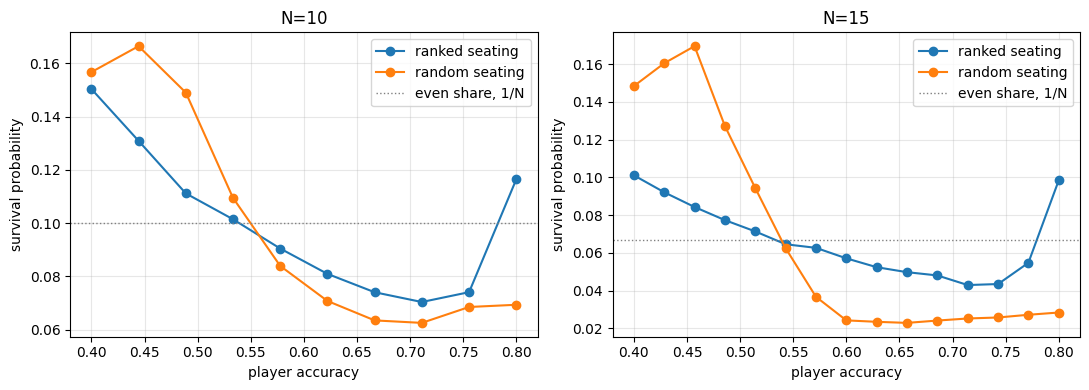

In [13]:
figure, axes = plt.subplots(1, len(PLAYER_COUNTS), figsize=(11, 4))
for index in range(len(PLAYER_COUNTS)):
    n = PLAYER_COUNTS[index]
    axis = axes[index]
    accuracies = accuracies_of(n)
    for arm in ARMS:
        axis.plot(accuracies, [POOLED[(n, arm)][a] for a in accuracies], marker="o",
                  label=arm + " seating")
    axis.axhline(1.0 / n, color="grey", linestyle=":", linewidth=1, label="even share, 1/N")
    axis.set_title("N=%d" % n)
    axis.set_xlabel("player accuracy")
    axis.set_ylabel("survival probability")
    axis.grid(alpha=0.3)
    axis.legend()
figure.tight_layout()
plt.show()

## Which reference does each arm resemble?

Three references, measured under each seating: `shoot_strongest`; `coin_flip`, which
discriminates on nothing; and `next_weaker`, the rule step 3 found the ranked agent sits on,
which under ranked seating always shoots left and under random seating does not. An arm matches a
reference only if its mean targeting distance is at most 0.10; otherwise it matches none.

In [14]:
for n in PLAYER_COUNTS:
    print("  N=%d" % n)
    for arm in ARMS:
        distances = {}
        for name, policy in [("shoot_strongest", shoot_strongest), ("coin_flip", coin_flip),
                             ("next_weaker", next_weaker)]:
            reference_rng = np.random.default_rng(0)
            game = GruelEnv(n=n, reward=REWARD, seating=arm, seed=7000 + n)
            records = play_episodes(game, policy, REFERENCE_EPISODES)
            distances[name] = profile_distance(ARM_TARGETING[(n, arm)],
                                               targeting_profile(records, n))
        nearest = min(distances, key=distances.get)
        print("     %-7s distance to shoot_strongest %.4f, to coin_flip %.4f, to next_weaker %.4f"
              % (arm, distances["shoot_strongest"], distances["coin_flip"], distances["next_weaker"]))
        if distances[nearest] <= MATCH_THRESHOLD:
            print("             -> matches %s" % nearest)
        else:
            print("             -> matches NONE; the nearest, %s, is %.4f away"
                  % (nearest, distances[nearest]))
    print()

  N=10


     ranked  distance to shoot_strongest 0.6272, to coin_flip 0.3274, to next_weaker 0.0424
             -> matches next_weaker


     random  distance to shoot_strongest 0.3024, to coin_flip 0.1975, to next_weaker 0.1893
             -> matches NONE; the nearest, next_weaker, is 0.1893 away

  N=15


     ranked  distance to shoot_strongest 0.7259, to coin_flip 0.3596, to next_weaker 0.0225
             -> matches next_weaker


     random  distance to shoot_strongest 0.2542, to coin_flip 0.2463, to next_weaker 0.1802
             -> matches NONE; the nearest, next_weaker, is 0.1802 away



## How long it took

Recorded because the next decision, whether to go to a larger field, depends on cost. The
runs were trained one after another in this notebook, on one CPU thread.

In [15]:
print("  %-28s %8s" % ("run", "minutes"))
for label in RUN_MINUTES:
    print("  %-28s %8.1f" % (label, RUN_MINUTES[label]))
print("  %-28s %8.1f" % ("total", sum(RUN_MINUTES.values())))

FIRST_RUN_KEY = (PLAYER_COUNTS[-1], "ranked", SEEDS[0])

  run                           minutes
  N=10 ranked seed 0                5.9
  N=10 ranked seed 1                6.8
  N=10 ranked seed 2                6.4
  N=10 random seed 0                6.1
  N=10 random seed 1                6.1
  N=10 random seed 2                6.3
  N=15 ranked seed 0                9.6
  N=15 ranked seed 1                9.7
  N=15 ranked seed 2                9.6
  N=15 random seed 0                9.1
  N=15 random seed 1                7.6
  N=15 random seed 2                7.5
  total                            90.8


## Reproducibility

Two random streams are reset, not one: the environment's, and torch's global stream, because a
trained policy samples its actions.

In [16]:
def measure_once():
    n = PLAYER_COUNTS[-1]
    torch.manual_seed(7000)
    game = GruelEnv(n=n, reward="terminal", seating="ranked", seed=9000)
    records = play_episodes(game, make_agent_policy(TRAINED[FIRST_RUN_KEY]), 400)
    rates = survival_by_accuracy(records, accuracies_of(n))
    return rates[sorted(rates)[0]]


first = measure_once()
second = measure_once()
print("  first  run:", format(first, ".6f"))
print("  second run:", format(second, ".6f"))
print("  identical:", first == second)

  first  run: 0.085000
  second run: 0.085000
  identical: True
